In [1]:
import pandas as pd
df = pd.read_csv('housepricedata.csv')
df.head()

,LotArea,OverallQual,OverallCond,TotalBsmtSF,FullBath,HalfBath,BedroomAbvGr,TotRmsAbvGrd,Fireplaces,GarageArea,AboveMedianPrice
0,8450,7,5,856,2,1,3,8,0,548,1
1,9600,6,8,1262,2,0,3,6,1,460,1
2,11250,7,5,920,2,1,3,6,1,608,1
3,9550,7,5,756,1,0,3,7,1,642,0
4,14260,8,5,1145,2,1,4,9,1,836,1


In [2]:
X = df.values[:,0:10]
Y =df.values[:,10]


In [3]:
from sklearn import preprocessing
min_max_scaler = preprocessing.MinMaxScaler()
X_scale = min_max_scaler.fit_transform(X)

In [4]:
X_scale

array([[0.0334198 , 0.66666667, 0.5       , ..., 0.5       , 0.        ,
        0.3864598 ],
       [0.03879502, 0.55555556, 0.875     , ..., 0.33333333, 0.33333333,
        0.32440056],
       [0.04650728, 0.66666667, 0.5       , ..., 0.33333333, 0.33333333,
        0.42877292],
       ...,
       [0.03618687, 0.66666667, 1.        , ..., 0.58333333, 0.66666667,
        0.17771509],
       [0.03934189, 0.44444444, 0.625     , ..., 0.25      , 0.        ,
        0.16925247],
       [0.04037019, 0.44444444, 0.625     , ..., 0.33333333, 0.        ,
        0.19464034]], shape=(1460, 10))

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_val_and_test, Y_train, Y_val_and_test = train_test_split(X_scale, Y, test_size=0.3)

X_val, X_test, Y_val, Y_test = train_test_split(X_val_and_test, Y_val_and_test, test_size=0.5) # تم تقسيم 30% على بينات  X_val_and_test, Y_val_and_test

print("X_train.shape : ",X_train.shape)
print("X_test.shape : ", X_test.shape)
print("X_val.shape : ", X_val.shape)
print("Y_val.shape : ", Y_val.shape)
print("Y_train.shape : ", Y_train.shape)
print("Y_test.shape : ", Y_test.shape)

X_train.shape :  (1022, 10)
X_test.shape :  (219, 10)
X_val.shape :  (219, 10)
Y_val.shape :  (219,)
Y_train.shape :  (1022,)
Y_test.shape :  (219,)


In [7]:
from keras.models import Sequential
from keras.layers import Dense 

model = Sequential([
    Dense(32, activation='relu', input_shape=(10,)),
    Dense(32,activation='relu'),
    Dense(1,activation='sigmoid') # طبقة الخرج  مناسبة لمسائل التصنيف الثنائي 
])


C:\ProgramData\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [10]:
model.compile(optimizer='sgd', loss='binary_crossentropy',metrics =['accuracy'])

In [11]:
hist = model.fit(X_train, Y_train,
          batch_size=32, epochs=10,  # only for testing 
          validation_data=(X_val, Y_val))

Epoch 1/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.3219 - loss: 0.7002 - val_accuracy: 0.4110 - val_loss: 0.6964
Epoch 2/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4609 - loss: 0.6949 - val_accuracy: 0.5251 - val_loss: 0.6908
Epoch 3/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5049 - loss: 0.6906 - val_accuracy: 0.5342 - val_loss: 0.6864
Epoch 4/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5068 - loss: 0.6870 - val_accuracy: 0.5342 - val_loss: 0.6826
Epoch 5/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5098 - loss: 0.6838 - val_accuracy: 0.5434 - val_loss: 0.6791
Epoch 6/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5078 - loss: 0.6807 - val_accuracy: 0.5571 - val_loss: 0.6758
Epoch 7/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5323 - loss: 0.6777 - val_accuracy: 0.5936 - val_loss: 0.6726
Epoch 8/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5509 - loss: 0.6745 - val_accuracy: 0.6575 - val_loss

In [12]:
test_loss,test_accuracy=model.evaluate(X_test, Y_test)

print(test_loss)
print(test_accuracy)

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7443 - loss: 0.6611 
0.6611025929450989
0.7442922592163086


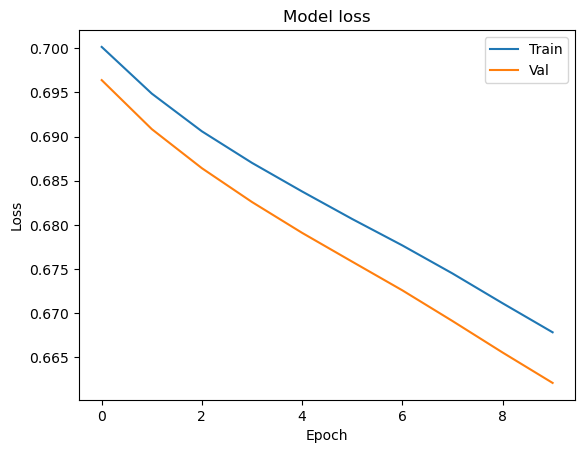

In [13]:
import matplotlib.pyplot as plt

plt.plot(hist.history['loss'])
plt.plot(hist.history['val_loss'])

plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Val'], loc='upper right')
plt.show()

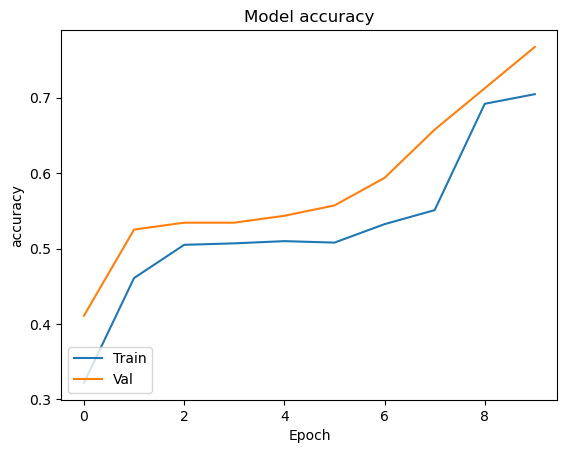

In [16]:
import matplotlib.pyplot as plt

plt.plot(hist.history['accuracy'])
plt.plot(hist.history['val_accuracy'])

plt.title('Model accuracy')
plt.ylabel('accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Val'], loc='lower left')
plt.show()

In [17]:
model_2 = Sequential([
    Dense(1000, activation='relu', input_shape=(10,)),
    Dense(1000, activation='relu'),
    Dense(1000, activation='relu'),
    Dense(1000, activation='relu'),
    Dense(1, activation='sigmoid'),
])

model_2.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])
hist_2 = model_2.fit(X_train, Y_train,
          batch_size=32, epochs=100,
          validation_data=(X_val, Y_val))

Epoch 1/100


C:\ProgramData\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - accuracy: 0.7544 - loss: 0.5037 - val_accuracy: 0.8219 - val_loss: 0.4130
Epoch 2/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.8366 - loss: 0.3803 - val_accuracy: 0.8721 - val_loss: 0.3420
Epoch 3/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.8630 - loss: 0.3175 - val_accuracy: 0.8676 - val_loss: 0.2865
Epoch 4/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.8796 - loss: 0.2971 - val_accuracy: 0.8721 - val_loss: 0.2476
Epoch 5/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.8826 - loss: 0.2797 - val_accuracy: 0.8858 - val_loss: 0.2351
Epoch 6/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.8885 - loss: 0.2596 - val_accuracy: 0.9041 - val_loss: 0.2189
Epoch 7/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.8875 - loss: 0.2752 - val_accuracy: 0.8767 - val_loss: 0.2672
Epoch 8/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.8885 - loss: 0.2637 - val_accuracy: 0.8858 - val_l

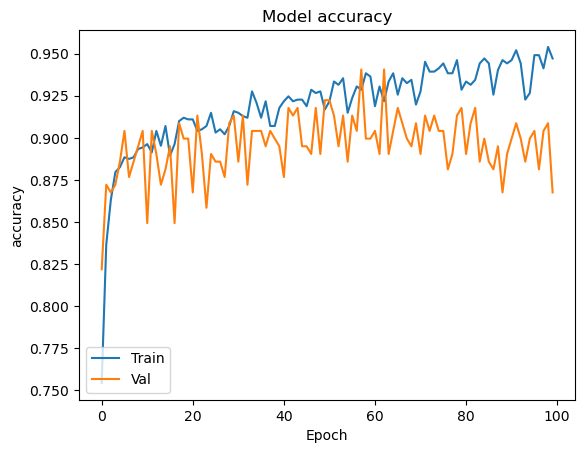

In [18]:
import matplotlib.pyplot as plt

plt.plot(hist_2.history['accuracy'])
plt.plot(hist_2.history['val_accuracy'])


plt.title('Model accuracy')
plt.ylabel('accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Val'], loc='lower left')
plt.show()




















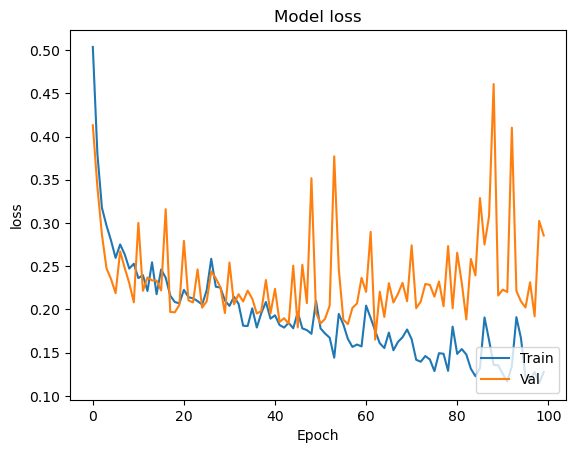

In [20]:
import matplotlib.pyplot as plt

plt.plot(hist_2.history['loss'])
plt.plot(hist_2.history['val_loss'])


plt.title('Model loss')
plt.ylabel('loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Val'], loc='lower right')
plt.show()




















In [23]:
from keras.layers import Dropout
from keras import regularizers

model_3 = Sequential([
    Dense(1000, activation='relu', kernel_regularizer = regularizers.l2(0.01), input_shape=(10,)),
    Dropout(0.3), #  للتخلص من مشكلة فرط التخصيص   OverFitting 
    Dense(1000, activation='relu', kernel_regularizer = regularizers.l2(0.01)),
    Dropout(0.3),
    Dense(1000, activation='relu', kernel_regularizer = regularizers.l2(0.01)),
    Dropout(0.3),
    Dense(1000, activation='relu', kernel_regularizer = regularizers.l2(0.01)),
    Dropout(0.3),
    Dense(1, activation='sigmoid', kernel_regularizer = regularizers.l2(0.01)),
])

model_3.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

hist_3 = model_3.fit(X_train, Y_train,
          batch_size=32, epochs=100,
          validation_data=(X_val, Y_val))

Epoch 1/100


C:\ProgramData\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 39ms/step - accuracy: 0.5646 - loss: 14.2538 - val_accuracy: 0.8356 - val_loss: 3.9366
Epoch 2/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy: 0.7730 - loss: 1.7220 - val_accuracy: 0.8539 - val_loss: 0.6356
Epoch 3/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy: 0.8542 - loss: 0.5670 - val_accuracy: 0.6667 - val_loss: 0.7018
Epoch 4/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.8444 - loss: 0.5566 - val_accuracy: 0.8082 - val_loss: 0.5811
Epoch 5/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.8620 - loss: 0.5188 - val_accuracy: 0.8858 - val_loss: 0.4736
Epoch 6/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.8571 - loss: 0.5045 - val_accuracy: 0.8584 - val_loss: 0.4587
Epoch 7/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.8728 - loss: 0.4837 - val_accuracy: 0.8950 - val_loss: 0.4261
Epoch 8/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.8738 - loss: 0.4721 - val_accuracy: 0.8539 - val_

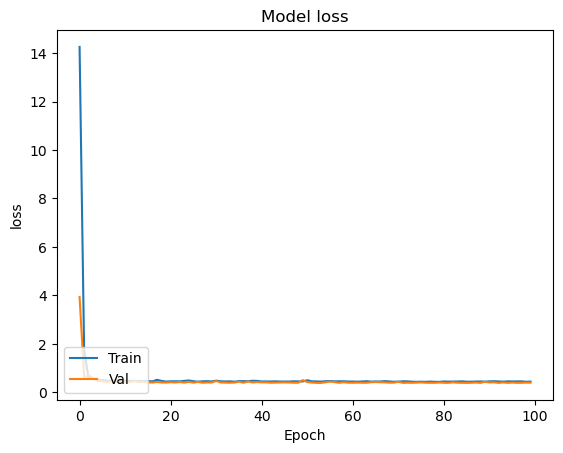

In [27]:



import matplotlib.pyplot as plt

plt.plot(hist_3.history['loss'])
plt.plot(hist_3.history['val_loss'])


plt.title('Model loss')
plt.ylabel('loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Val'], loc='lower left')
# plt.ylim(top=1,2 ,bottom=0)
plt.show()




















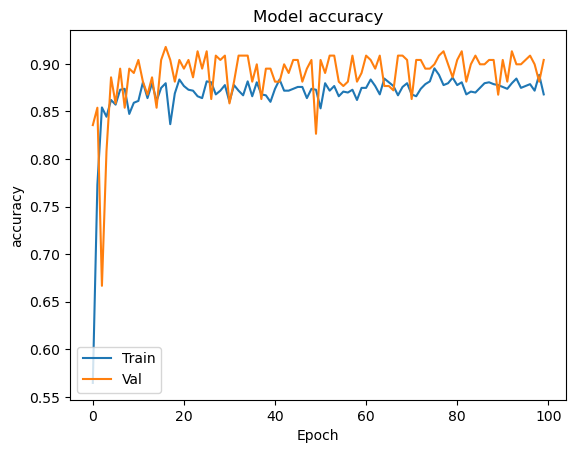

In [28]:



import matplotlib.pyplot as plt

plt.plot(hist_3.history['accuracy'])
plt.plot(hist_3.history['val_accuracy'])


plt.title('Model accuracy')
plt.ylabel('accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Val'], loc='lower left')
# plt.ylim(top=1,2 ,bottom=0)
plt.show()




















In [29]:
from sklearn.metrics import recall_score , f1_score , precision_score

In [31]:
y_pred = model.predict(X_test)


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 


In [32]:
y_pred_classes=[]
for prob in y_pred:
    if prob >= 0.5:
        y_pred_classes.append(1)
    else:
        y_pred_classes.append(0)
    

In [33]:
precision = precision_score(Y_test, y_pred_classes)

recall = recall_score(Y_test, y_pred_classes)

f1 = f1_score(Y_test, y_pred_classes)

print("Precision:", round(precision*100,0))
print("Recall:", round(recall*100,0))
print("F1 Score:", round(f1*100,0))

Precision: 67.0
Recall: 95.0
F1 Score: 79.0


# Importint 

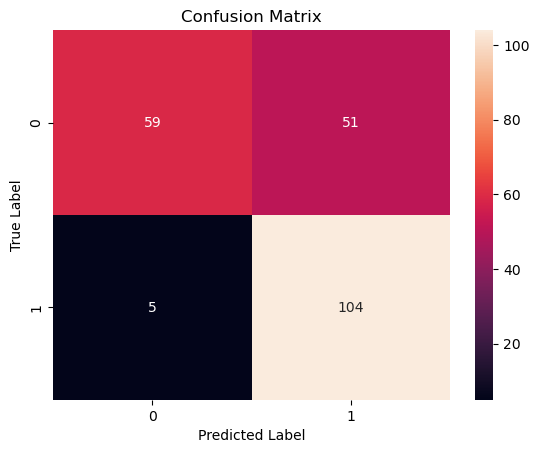

In [34]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

confusion_mat = confusion_matrix(Y_test, y_pred_classes)

sns.heatmap(confusion_mat, annot=True, fmt='d')
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

In [35]:
model.save('Houses_model.keras')

In [36]:
from joblib import dump 

dump(min_max_scaler, "Houses_min_max_scaler.pkl")

['Houses_min_max_scaler.pkl']

In [37]:
import numpy as np 

new_house = np.array([[100, 6, 6, 800 , 2 ,2 ,3 ,7 ,1 ,500]])


In [40]:
from joblib import load 

min_max_scaler_loaded = load("Houses_min_max_scaler.pkl")

new_house = min_max_scaler.transform(new_house)
new_house

array([[-0.00560892,  0.55555556,  0.625     ,  0.1309329 ,  0.66666667,
         1.        ,  0.375     ,  0.41666667,  0.33333333,  0.35260931]])

In [42]:
from keras.models import load_model 

loaded_model = load_model("Houses_model.keras")

In [43]:
new_predictions_proba = loaded_model.predict(new_house)


new_prediction = (new_predictions_proba > 0.5) 
print(new_prediction)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
[[ True]]
